# DINOv3-Guided YOLOv12m Pretraining (Part B, SSL)

**Student:** Random YOLOv12m backbone (from `yolo12m.yaml`)
**Teacher:** Frozen released DINOv3 ViT-B/16
**Data:** AgroPest-12-PartB-Safe SSL pool (9,180 images, label-free)
**This Colab test:** single T4 GPU, verify the pipeline end-to-end for 1 epoch.

---

**Status (from previous session, see scratchpad.py):**
- deps ✓ data ✓ teacher weights ✓ CONFIG ✓ core module ✓ teacher-sanity ✓
- remaining: preview, finite-loss sanity, smoke train, 1-epoch train, export, diagnostics.

In [ ]:
import subprocess, sys, torch
from pathlib import Path

print("torch:", torch.__version__, "cuda:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("gpu:", torch.cuda.get_device_name(0))

torch: 2.11.0+cu128 cuda: True
gpu: Tesla T4
MISSING /content/partb_safe/ssl_pool/images
MISSING /root/.cache/kagglehub/datasets/mrifatrashid/dinov3-weigths/versions/2/dinov3_vitb16_pretrain_lvd1689m-73cec8be.pth
MISSING /content/partB_04a_dinov3_yolo12m/dinov3_core.py
import FAIL ultralytics
import FAIL torchmetrics
import FAIL scikit-learn
import OK seaborn


In [ ]:
import subprocess, sys

subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", "ultralytics>=8.4.96", "scikit-learn", "seaborn"])
for pkg in ["torchmetrics"]:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
print("deps ready")

deps ready


In [ ]:
# Download AgroPest-12-PartB-Safe (public) — SSL pool only for pretraining.
import os, shutil
from pathlib import Path

DATA_ROOT = Path("/content/partb_safe")
DATA_ROOT.mkdir(exist_ok=True)
SSL_DST = DATA_ROOT / "ssl_pool" / "images"

if not SSL_DST.is_dir() or len(list(SSL_DST.iterdir())) < 9000:
    import kagglehub
    K = Path(kagglehub.dataset_download("sadikshahriar/agropest-12-partb-safe"))
    base = K / "AgroPest-12-PartB-Safe" if (K / "AgroPest-12-PartB-Safe").exists() else K
    src = base / "ssl_pool" / "images"
    if SSL_DST.exists():
        shutil.rmtree(SSL_DST)
    SSL_DST.mkdir(parents=True, exist_ok=True)
    for f in src.iterdir():
        shutil.copy2(f, SSL_DST / f.name)
print("ssl images:", len(list(SSL_DST.iterdir())))

ssl images: 9180


In [ ]:
# DINOv3 ViT-B/16 teacher weights from the public Kaggle mirror (used by the reference notebook).
import kagglehub
from pathlib import Path

CKPT = Path("/root/.cache/kagglehub/datasets/mrifatrashid/dinov3-weigths/versions/2/dinov3_vitb16_pretrain_lvd1689m-73cec8be.pth")
if not CKPT.is_file():
    w = Path(kagglehub.dataset_download("mrifatrashid/dinov3-weigths"))
    CKPT = next(p for p in w.rglob("dinov3_vitb16_*.pth"))
print("teacher ckpt:", CKPT)
print("exists:", CKPT.is_file(), "size MB:", round(CKPT.stat().st_size / 1e6, 1))

teacher ckpt: /root/.cache/kagglehub/datasets/mrifatrashid/dinov3-weigths/versions/2/dinov3_vitb16_pretrain_lvd1689m-73cec8be.pth
exists: True size MB: 342.9


In [ ]:
from dataclasses import asdict, dataclass
from pathlib import Path

@dataclass
class CFG:
    # --- data (Colab test paths; Kaggle conversion swaps these) ---
    partb_root: str = "/content/partb_safe"
    ssl_pool: str = "/content/partb_safe/ssl_pool/images"
    output_dir: str = "/content/partB_04a_dinov3_yolo12m"
    teacher_ckpt: str = "/root/.cache/kagglehub/datasets/mrifatrashid/dinov3-weigths/versions/2/dinov3_vitb16_pretrain_lvd1689m-73cec8be.pth"

    seed: int = 445                     # shared Part B seed
    model_yaml: str = "yolo12m.yaml"    # random student; never yolo12m.pt here

    # --- DINOv3 teacher (ViT-B/16) ---
    teacher_name: str = "dinov3_vitb16"
    image_size: int = 224               # 224 -> 14x14 teacher patch grid
    teacher_embed_dim: int = 768        # ViT-B/16 hidden dim
    teacher_num_registers: int = 4      # DINOv3 storage/register tokens

    # --- training (1 GPU Colab test) ---
    epochs: int = 1                     # Kaggle version: 30 (Part B budget)
    per_gpu_batch: int = 16             # fits 1x T4 with frozen teacher (fp16)
    grad_accum: int = 2                 # effective batch = 32
    workers: int = 2
    amp: bool = True
    smoke_images: int = 400             # None = full 9,180 SSL pool

    # --- optimizer ---
    learning_rate: float = 3e-4
    min_learning_rate: float = 3e-6
    warmup_epochs: int = 1
    warmup_start_factor: float = 0.10
    weight_decay: float = 1e-4
    gradient_clip_norm: float = 5.0

    # --- objectives ---
    global_loss_weight: float = 1.0     # CLS-token cosine regression
    dense_loss_weight: float = 1.0      # 14x14 patch cosine regression

    # --- diagnostics ---
    diagnostic_images: int = 240
    retrieval_queries: int = 4
    retrieval_neighbors: int = 5

cfg = CFG()
print(cfg)

CFG(partb_root='/content/partb_safe', ssl_pool='/content/partb_safe/ssl_pool/images', output_dir='/content/partB_04a_dinov3_yolo12m', teacher_ckpt='/root/.cache/kagglehub/datasets/mrifatrashid/dinov3-weigths/versions/2/dinov3_vitb16_pretrain_lvd1689m-73cec8be.pth', seed=445, model_yaml='yolo12m.yaml', teacher_name='dinov3_vitb16', image_size=224, teacher_embed_dim=768, teacher_num_registers=4, epochs=1, per_gpu_batch=16, grad_accum=2, workers=2, amp=True, smoke_images=400, learning_rate=0.0003, min_learning_rate=3e-06, warmup_epochs=1, warmup_start_factor=0.1, weight_decay=0.0001, gradient_clip_norm=5.0, global_loss_weight=1.0, dense_loss_weight=1.0, diagnostic_images=240, retrieval_queries=4, retrieval_neighbors=5)


In [ ]:
from pathlib import Path
from textwrap import dedent

OUTPUT_DIR = Path(cfg.output_dir)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CORE_MODULE = OUTPUT_DIR / "dinov3_core.py"
CORE_MODULE.write_text(dedent(r'''
    import copy
    import csv
    import json
    import math
    import os
    import random
    import time
    from pathlib import Path

    import numpy as np
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    from PIL import Image
    from torch.utils.data import DataLoader, Dataset
    from torchvision import transforms
    from ultralytics import YOLO

    IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    IMAGENET_MEAN = (0.485, 0.456, 0.406)
    IMAGENET_STD = (0.229, 0.224, 0.225)

    def seed_everything(seed):
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True

    def list_ssl_images(image_dir):
        paths = sorted(path for path in Path(image_dir).iterdir()
                       if path.is_file() and path.suffix.lower() in IMAGE_SUFFIXES)
        return paths

    def cos_regression_loss(pred, target, dim):
        return (2.0 - 2.0 * F.cosine_similarity(pred, target, dim=dim)).mean()

    class YOLOBackboneEncoder(nn.Module):
        def __init__(self, yolo_task_model):
            super().__init__()
            backbone = getattr(yolo_task_model, "yaml", {}).get("backbone", [])
            if not backbone:
                raise ValueError("yaml backbone missing")
            self.backbone_end = len(backbone)
            self.layers = nn.ModuleList(list(yolo_task_model.model[:self.backbone_end]))
            self.save = set(getattr(yolo_task_model, "save", []))

        def forward_feature_map(self, x):
            saved = []
            for module in self.layers:
                source = getattr(module, "f", -1)
                if source != -1:
                    x = saved[source] if isinstance(source, int) else [x if item == -1 else saved[item] for item in source]
                x = module(x)
                saved.append(x if getattr(module, "i", -1) in self.save else None)
            if not isinstance(x, torch.Tensor):
                raise TypeError("backbone output must be a tensor")
            return x

        def forward(self, x):
            return F.adaptive_avg_pool2d(self.forward_feature_map(x), 1).flatten(1)

    class DINOv3FeatureTeacher(nn.Module):
        def __init__(self, teacher, embed_dim, grid):
            super().__init__()
            self.teacher = teacher
            self.embed_dim = embed_dim
            self.grid = grid
            for p in self.teacher.parameters():
                p.requires_grad_(False)
            self.teacher.eval()

        @torch.no_grad()
        def forward(self, x):
            out = self.teacher.forward_features(x)
            cls = out["x_norm_clstoken"]
            patches = out["x_norm_patchtokens"]
            patches = patches.permute(0, 2, 1).view(x.shape[0], self.embed_dim, self.grid, self.grid)
            return cls, patches

    class DINOv3DistillationModel(nn.Module):
        def __init__(self, encoder, feature_dim, cfg_d):
            super().__init__()
            self.encoder = encoder
            self.global_head = nn.Sequential(
                nn.Linear(feature_dim, feature_dim, bias=False),
                nn.BatchNorm1d(feature_dim),
                nn.ReLU(inplace=True),
                nn.Linear(feature_dim, cfg_d["teacher_embed_dim"]),
            )
            self.dense_head = nn.Sequential(
                nn.Conv2d(feature_dim, cfg_d["teacher_embed_dim"], 1),
            )
            self.global_loss_weight = cfg_d["global_loss_weight"]
            self.dense_loss_weight = cfg_d["dense_loss_weight"]

        def forward(self, images, teacher_cls, teacher_patches):
            feat = self.encoder.forward_feature_map(images)
            global_vec = self.global_head(F.adaptive_avg_pool2d(feat, 1).flatten(1))
            dense_map = F.interpolate(self.dense_head(feat), size=teacher_patches.shape[-2:],
                                      mode="bilinear", align_corners=False)
            loss_global = cos_regression_loss(F.normalize(global_vec, dim=1),
                                              F.normalize(teacher_cls, dim=1), dim=1)
            loss_dense = cos_regression_loss(F.normalize(dense_map, dim=1),
                                             F.normalize(teacher_patches, dim=1), dim=1)
            loss = self.global_loss_weight * loss_global + self.dense_loss_weight * loss_dense
            return loss, {"global": loss_global.detach(), "dense": loss_dense.detach(), "total": loss.detach()}

    class SSLImageDataset(Dataset):
        def __init__(self, paths, transform):
            self.paths, self.transform = list(paths), transform

        def __len__(self):
            return len(self.paths)

        def __getitem__(self, index):
            with Image.open(self.paths[index]) as image:
                return self.transform(image.convert("RGB"))

    def build_transform(cfg_d):
        return transforms.Compose([
            transforms.RandomResizedCrop(cfg_d["image_size"], scale=(0.50, 1.0), ratio=(0.75, 1.333333)),
            transforms.RandomHorizontalFlip(p=0.50),
            transforms.RandomApply([transforms.ColorJitter(0.35, 0.35, 0.20, 0.06)], p=0.80),
            transforms.RandomGrayscale(p=0.10),
            transforms.RandomApply([transforms.GaussianBlur(kernel_size=23, sigma=(0.1, 2.0))], p=0.50),
            transforms.ToTensor(),
            transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
        ])

    def build_student(cfg_d, device):
        detector = YOLO(cfg_d["model_yaml"]).model.to(device)
        encoder = YOLOBackboneEncoder(detector).to(device)
        with torch.no_grad():
            feature_dim = encoder(torch.zeros(2, 3, cfg_d["image_size"], cfg_d["image_size"], device=device)).shape[1]
        return encoder, feature_dim

    def is_frozen(module):
        return all(not p.requires_grad for p in module.parameters())

    def cpu_state_dict(module):
        return {k: v.detach().cpu() for k, v in module.state_dict().items()}

    def lease_lr(cfg_d, step, total_steps):
        warmup = cfg_d["warmup_epochs"] * cfg_d["steps_per_epoch"]
        if step < warmup:
            progress = (step + 1) / max(1, warmup)
            factor = cfg_d["warmup_start_factor"] + (1.0 - cfg_d["warmup_start_factor"]) * progress
            return cfg_d["learning_rate"] * factor
        progress = (step - warmup) / max(1, total_steps - warmup - 1)
        cosine = 0.5 * (1.0 + math.cos(math.pi * min(progress, 1.0)))
        return cfg_d["min_learning_rate"] + (cfg_d["learning_rate"] - cfg_d["min_learning_rate"]) * cosine

    def save_epoch_state(output_dir, epoch, best_loss, model, optimizer, scaler, feature_dim, cfg_d):
        state = {
            "format_version": 4, "epoch": epoch, "best_loss": best_loss,
            "yolo_model": cfg_d["model_yaml"], "feature_dim": feature_dim,
            "teacher_name": cfg_d["teacher_name"], "image_size": cfg_d["image_size"],
            "encoder_state_dict": cpu_state_dict(model.encoder),
            "global_head_state_dict": cpu_state_dict(model.global_head),
            "dense_head_state_dict": cpu_state_dict(model.dense_head),
            "optimizer_state_dict": optimizer.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "config": cfg_d,
        }
        torch.save(state, output_dir / "last_ssl.pt")
        return state

    def train_single_gpu(cfg_d, teacher, device):
        seed_everything(cfg_d["seed"])
        output_dir = Path(cfg_d["output_dir"])
        paths = list_ssl_images(cfg_d["ssl_pool"])
        if cfg_d.get("smoke_images"):
            paths = paths[:cfg_d["smoke_images"]]
        dataset = SSLImageDataset(paths, build_transform(cfg_d))
        loader = DataLoader(dataset, batch_size=cfg_d["per_gpu_batch"], shuffle=True,
                            num_workers=cfg_d["workers"], pin_memory=True, drop_last=True)
        cfg_d["steps_per_epoch"] = len(loader)
        total_steps = len(loader) * cfg_d["epochs"]

        encoder, feature_dim = build_student(cfg_d, device)
        model = DINOv3DistillationModel(encoder, feature_dim, cfg_d).to(device)
        optimizer = torch.optim.AdamW(model.parameters(), lr=cfg_d["learning_rate"],
                                      weight_decay=cfg_d["weight_decay"])
        scaler = torch.amp.GradScaler("cuda", enabled=cfg_d["amp"])
        teacher = teacher.to(device)

        best_loss, start_epoch, global_step = float("inf"), 0, 0
        history = []
        last_path = output_dir / "last_ssl.pt"

        for epoch in range(start_epoch, cfg_d["epochs"]):
            model.train()
            epoch_loss, epoch_global, epoch_dense = 0.0, 0.0, 0.0
            epoch_start = time.time()
            for step, images in enumerate(loader):
                images = images.to(device, non_blocking=True)
                with torch.no_grad():
                    teacher_cls, teacher_patches = teacher(images.float())
                with torch.amp.autocast("cuda", enabled=cfg_d["amp"]):
                    loss, parts = model(images, teacher_cls, teacher_patches)
                scaler.scale(loss).backward()
                if (step + 1) % cfg_d["grad_accum"] == 0 or (step + 1) == len(loader):
                    scaler.unscale_(optimizer)
                    torch.nn.utils.clip_grad_norm_(model.parameters(), cfg_d["gradient_clip_norm"])
                    scaler.step(optimizer)
                    scaler.update()
                    optimizer.zero_grad(set_to_none=True)
                    lr = lease_lr(cfg_d, global_step, total_steps)
                    for g in optimizer.param_groups:
                        g["lr"] = lr
                    global_step += 1
                epoch_loss += parts["total"].item()
                epoch_global += parts["global"].item()
                epoch_dense += parts["dense"].item()
            epoch_loss /= (step + 1)
            epoch_global /= (step + 1)
            epoch_dense /= (step + 1)
            history.append({"epoch": epoch, "loss": epoch_loss, "global_loss": epoch_global,
                            "dense_loss": epoch_dense, "seconds": round(time.time() - epoch_start, 1)})
            if epoch_loss < best_loss:
                best_loss = epoch_loss
                torch.save(save_epoch_state(output_dir, epoch, best_loss, model, optimizer, scaler, feature_dim, cfg_d),
                           output_dir / "best_ssl.pt")
            torch.save(save_epoch_state(output_dir, epoch, best_loss, model, optimizer, scaler, feature_dim, cfg_d),
                       output_dir / "last_ssl.pt")
            with open(output_dir / "history.csv", "w") as f:
                writer = csv.DictWriter(f, fieldnames=list(history[0].keys()))
                writer.writeheader()
                writer.writerows(history)
            print(f"epoch {epoch+1}/{cfg_d['epochs']} loss {epoch_loss:.4f} "
                  f"(g {epoch_global:.4f} d {epoch_dense:.4f}) best {best_loss:.4f} "
                  f"[{history[-1]['seconds']:.0f}s]", flush=True)
        return {"best_loss": best_loss, "history": history}
    '''))

import importlib.util
spec = importlib.util.spec_from_file_location("dinov3_core", CORE_MODULE)
core = importlib.util.module_from_spec(spec)
spec.loader.exec_module(core)
print("core module loaded; train_single_gpu:", hasattr(core, "train_single_gpu"))

Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
core module loaded; train_single_gpu: True


In [ ]:
import random
import numpy as np
import torch
import torch.nn.functional as F
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.manifold import TSNE

core.seed_everything(cfg.seed)
torch.set_float32_matmul_precision("high")
sns.set_theme(style="whitegrid")

SSL_PATH = Path(cfg.ssl_pool)
assert SSL_PATH.is_dir(), f"missing {SSL_PATH}"
ssl_paths = core.list_ssl_images(SSL_PATH)
assert len(ssl_paths) == 9180, f"expected 9,180 SSL-pool images, got {len(ssl_paths)}"
assert not list(SSL_PATH.parent.rglob("*.txt")), "SSL pool must never contain labels"
print("SSL-pool images:", len(ssl_paths))

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE)

torch.hub._validate_not_a_forked_repo = lambda *a, **k: True
raw_teacher = torch.hub.load("facebookresearch/dinov3", "dinov3_vitb16", pretrained=False)
sd = torch.load(cfg.teacher_ckpt, map_location="cpu", weights_only=False)
if "state_dict" in sd:
    sd = sd["state_dict"]
raw_teacher.load_state_dict(sd)
teacher = core.DINOv3FeatureTeacher(raw_teacher, cfg.teacher_embed_dim,
                                    cfg.image_size // 16).to(DEVICE)
assert core.is_frozen(teacher), "teacher must be frozen"

probe_x = torch.randn(2, 3, cfg.image_size, cfg.image_size, device=DEVICE)
with torch.no_grad():
    cls, patches = teacher(probe_x)
print("teacher cls:", tuple(cls.shape), "patches:", tuple(patches.shape))
assert cls.shape == (2, 768) and patches.shape == (2, 768, 14, 14)
print("teacher OK, frozen:", core.is_frozen(teacher))

SSL-pool images: 9180
device: cuda
Downloading: "https://github.com/facebookresearch/dinov3/zipball/main" to /root/.cache/torch/hub/main.zip
teacher cls: (2, 768) patches: (2, 768, 14, 14)
teacher OK, frozen: True


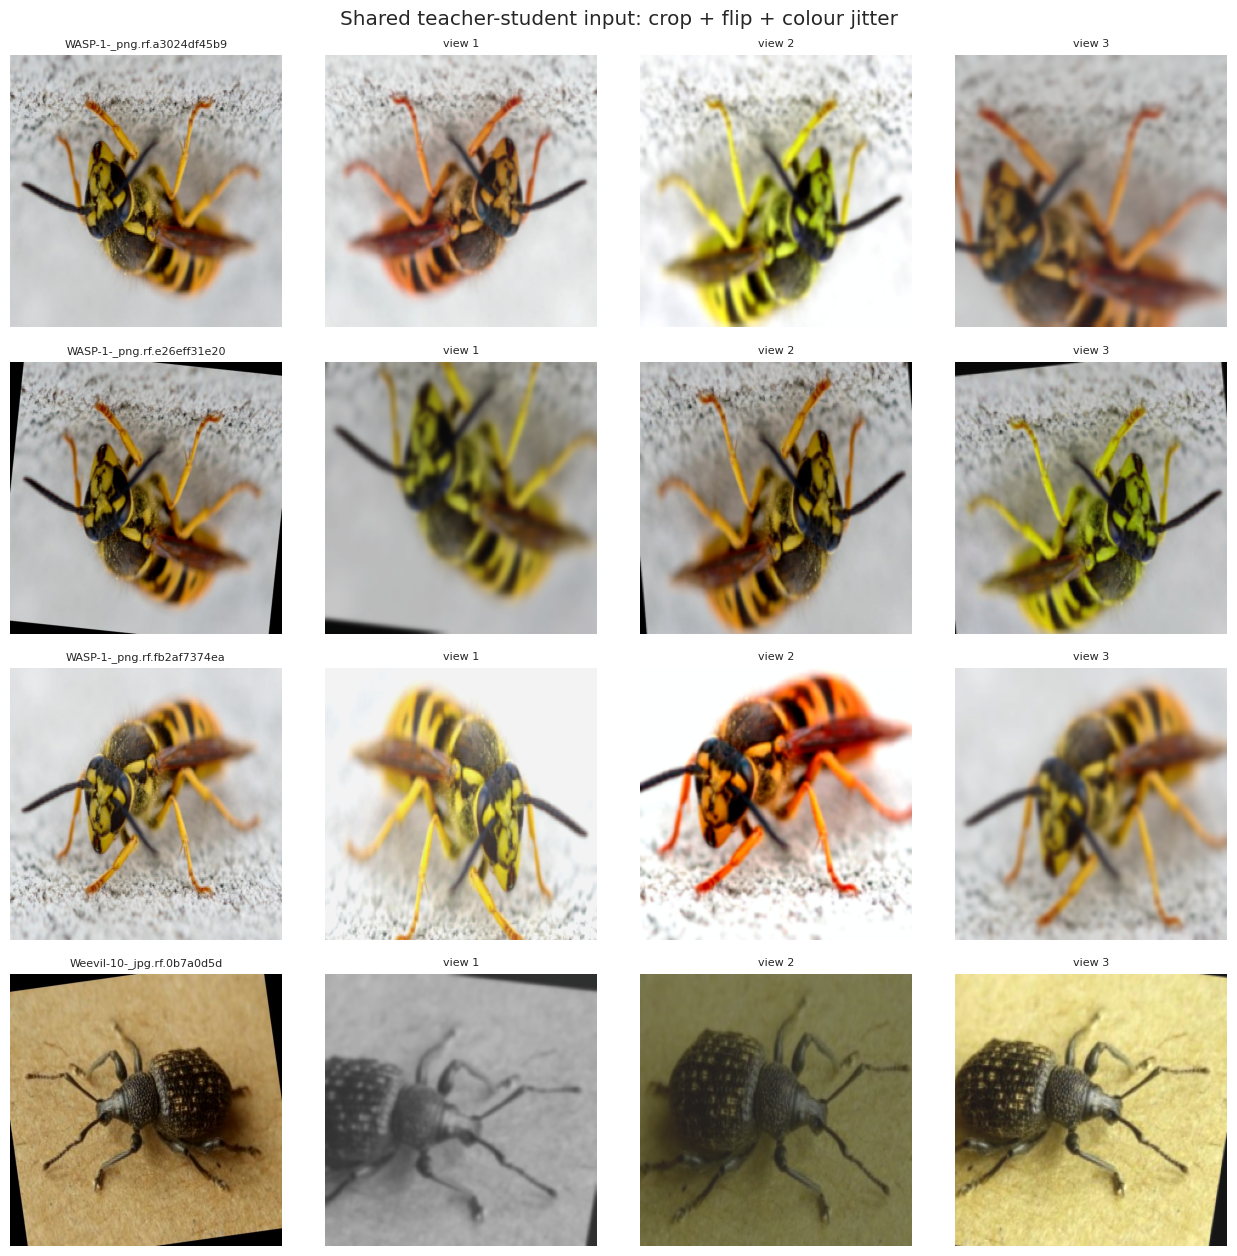

In [13]:
from pathlib import Path
from PIL import Image

transform = core.build_transform({
    "image_size": cfg.image_size, "crop_scale_min": 0.50,
    "horizontal_flip_probability": 0.50, "color_jitter_probability": 0.80,
    "color_jitter_brightness": 0.35, "color_jitter_contrast": 0.35,
    "color_jitter_saturation": 0.20, "color_jitter_hue": 0.06,
    "grayscale_probability": 0.10, "blur_probability": 0.50,
})

sample = ssl_paths[:4]
n_views = 3
mean = np.array([0.485, 0.456, 0.406]).reshape(3, 1, 1)
std = np.array([0.229, 0.224, 0.225]).reshape(3, 1, 1)

fig, axes = plt.subplots(len(sample), n_views + 1, figsize=(3.2 * (n_views + 1), 3.2 * len(sample)))
for r, path in enumerate(sample):
    with Image.open(path) as im:
        im = im.convert("RGB")
        base = np.array(im) / 255.0
    axes[r, 0].imshow(base)
    axes[r, 0].set_title(path.name[:26], fontsize=8)
    axes[r, 0].axis("off")
    for c in range(1, n_views + 1):
        view = transform(im)
        axes[r, c].imshow((view.numpy() * std + mean).clip(0, 1).transpose(1, 2, 0))
        axes[r, c].set_title(f"view {c}", fontsize=8)
        axes[r, c].axis("off")
plt.suptitle("Shared teacher-student input: crop + flip + colour jitter")
plt.tight_layout()
plt.show()

In [ ]:
# Finite-loss + gradient sanity check on a 2-image batch.
probe_detector = None
encoder, feature_dim = core.build_student({
    "model_yaml": cfg.model_yaml, "image_size": cfg.image_size,
}, DEVICE)
probe_model = core.DINOv3DistillationModel(encoder, feature_dim, {
    "teacher_embed_dim": cfg.teacher_embed_dim,
    "global_loss_weight": cfg.global_loss_weight,
    "dense_loss_weight": cfg.dense_loss_weight,
}).to(DEVICE).train()

probe_images = torch.stack([transform(sample_img) for sample_img in [
    Image.open(path).convert("RGB") for path in ssl_paths[:2]]]).to(DEVICE)

with torch.no_grad():
    t_cls, t_patches = teacher(probe_images.float())
with torch.amp.autocast("cuda", enabled=cfg.amp):
    probe_loss, parts = probe_model(probe_images, t_cls, t_patches)
assert torch.isfinite(probe_loss), f"Non-finite loss: {probe_loss.item()}"
probe_loss.backward()

student_grad_norm = sum(
    p.grad.detach().norm().item() for p in probe_model.encoder.parameters() if p.grad is not None)
teacher_grads = sum(p.grad is not None for p in teacher.parameters())
assert student_grad_norm > 0, "student got no gradients"
assert teacher_grads == 0, "frozen teacher received gradients"

print(pd.Series({
    "unit_test_images": 2,
    "feature_dim": feature_dim,
    "loss_total": round(float(parts["total"]), 4),
    "loss_global": round(float(parts["global"]), 4),
    "loss_dense": round(float(parts["dense"]), 4),
    "student_grad_norm": round(student_grad_norm, 4),
    "teacher_grad_params": teacher_grads,
    "amp": cfg.amp,
}))
del probe_model, probe_images, probe_loss
torch.cuda.empty_cache()